In [1]:
print("hello")

hello


In [3]:
import pandas as pd

path = r"C:\Users\acer\OneDrive\Documents\onlline retail ii uci~\rfm.csv"
rfm = pd.read_csv(path)
print(rfm.shape)
rfm.head()

(5878, 4)


,customer_id,recency,frequency,monetary
0,12346,326,12,77556.46
1,12347,3,8,5633.32
2,12348,76,5,2019.40
3,12349,19,4,4428.69
4,12350,311,1,334.40


In [4]:
rfm[["recency", "frequency", "monetary"]].describe()

,recency,frequency,monetary
count,5878.000000,5878.000000,5878.000000
mean,201.866791,6.289384,3018.616734
std,209.353961,13.009406,14737.731038
min,1.000000,1.000000,2.950000
25%,26.000000,1.000000,348.762500
50%,96.000000,3.000000,898.915000
75%,380.000000,7.000000,2307.090000
max,739.000000,398.000000,608821.650000


In [5]:
import numpy as np
from sklearn.preprocessing import StandardScaler

rfm_log = np.log1p(rfm[["recency", "frequency", "monetary"]])

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

print(rfm_scaled.shape)
rfm_log.describe()

(5878, 3)


,recency,frequency,monetary
count,5878.000000,5878.000000,5878.000000
mean,4.473965,1.549588,6.836550
std,1.530915,0.809447,1.387864
min,0.693147,0.693147,1.373716
25%,3.295837,0.693147,5.857254
50%,4.574711,1.386294,6.802300
75%,5.942799,2.079442,7.744175
max,6.606650,5.988961,13.319282


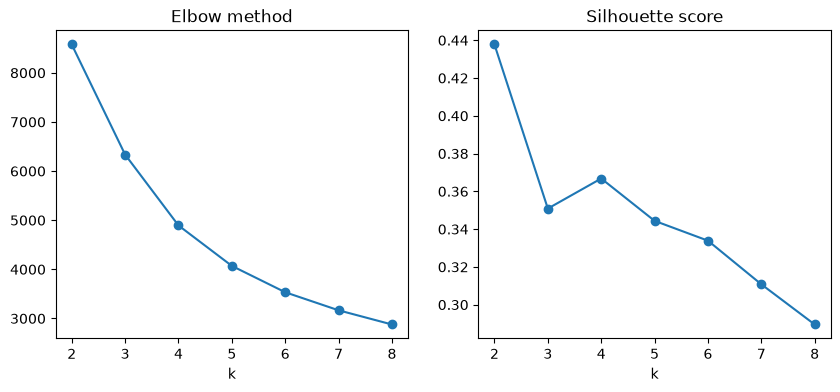

In [6]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

inertia = []
sil = []
ks = range(2, 9)

for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(rfm_scaled)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(rfm_scaled, labels, sample_size=3000, random_state=42))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(ks, inertia, marker="o")
ax[0].set_title("Elbow method")
ax[0].set_xlabel("k")
ax[1].plot(ks, sil, marker="o")
ax[1].set_title("Silhouette score")
ax[1].set_xlabel("k")
plt.show()

In [7]:
km = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm["cluster"] = km.fit_predict(rfm_scaled)

summary = rfm.groupby("cluster").agg(
    customers=("customer_id", "count"),
    avg_recency=("recency", "mean"),
    avg_frequency=("frequency", "mean"),
    avg_monetary=("monetary", "mean")
).round(1)

summary

,customers,avg_recency,avg_frequency,avg_monetary
cluster,,,,
0,1967,396.9,1.4,324.1
1,1194,28.1,19.3,10979.2
2,1260,29.1,3.0,868.4
3,1457,230.4,5.1,1992.2


In [9]:
names = {0: "Hibernating", 1: "Champions", 2: "Potential Loyalists", 3: "At-Risk"}
rfm["segment"] = rfm["cluster"].map(names)

seg = rfm.groupby("segment").agg(
    customers=("customer_id", "count"),
    revenue=("monetary", "sum")
)
seg["customer_pct"] = (100 * seg["customers"] / seg["customers"].sum()).round(1)
seg["revenue_pct"] = (100 * seg["revenue"] / seg["revenue"].sum()).round(1)
seg

rfm.to_csv(r"C:\Users\acer\OneDrive\Documents\onlline retail ii uci~\rfm_segments.csv", index=False)

In [10]:
seg

,customers,revenue,customer_pct,revenue_pct
segment,,,,
At-Risk,1457,2902567.11,24.8,16.4
Champions,1194,13109113.49,20.3,73.9
Hibernating,1967,637549.77,33.5,3.6
Potential Loyalists,1260,1094198.79,21.4,6.2


In [11]:
years = 2.0  # the data covers about 2 years

rfm["historical_clv"] = rfm["monetary"]
rfm["aov"] = rfm["monetary"] / rfm["frequency"]
rfm["annual_freq"] = rfm["frequency"] / years

lifespan = {"Champions": 3, "Potential Loyalists": 2, "At-Risk": 1, "Hibernating": 0.5}
rfm["predictive_clv"] = rfm["aov"] * rfm["annual_freq"] * rfm["segment"].map(lifespan)

clv = rfm.groupby("segment").agg(
    customers=("customer_id", "count"),
    avg_historical=("historical_clv", "mean"),
    avg_predictive=("predictive_clv", "mean")
).round(0)

rfm.to_csv(r"C:\Users\acer\OneDrive\Documents\onlline retail ii uci~\rfm_segments.csv", index=False)
clv

,customers,avg_historical,avg_predictive
segment,,,
At-Risk,1457,1992.0,996.0
Champions,1194,10979.0,16469.0
Hibernating,1967,324.0,81.0
Potential Loyalists,1260,868.0,868.0
